In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

import joblib



In [2]:
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")



In [4]:
print(df.shape)

(7043, 21)


In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
print(df.isnull().sum().sort_values(ascending=False))

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [9]:
print(df.duplicated().sum())



0


In [10]:
print(df["Churn"].value_counts())

print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [11]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df["TotalCharges"].isnull().sum())

11


In [12]:
missing_rows = df[df["TotalCharges"].isnull()]

display(
    missing_rows[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [13]:
df.loc[df["TotalCharges"].isnull(),"TotalCharges"] = 0

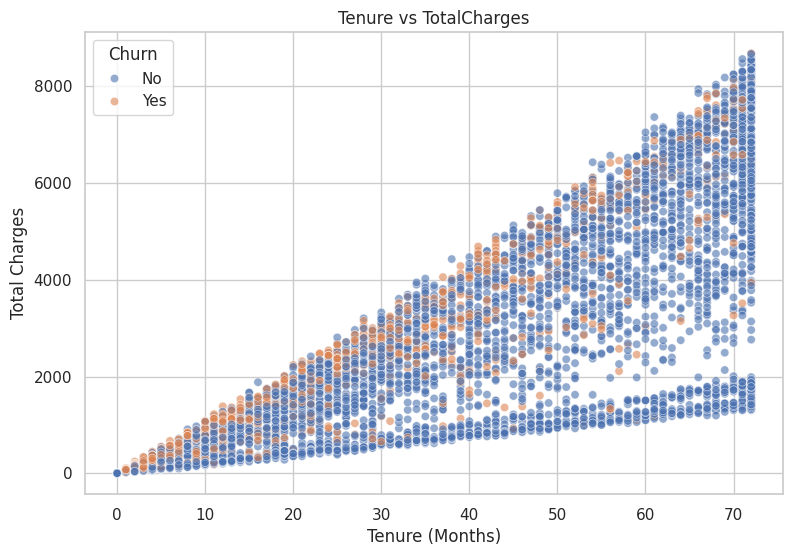

In [14]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="tenure",
    y="TotalCharges",
    hue="Churn",
    alpha=0.6
)

plt.title("Tenure vs TotalCharges")
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Charges")
plt.show()

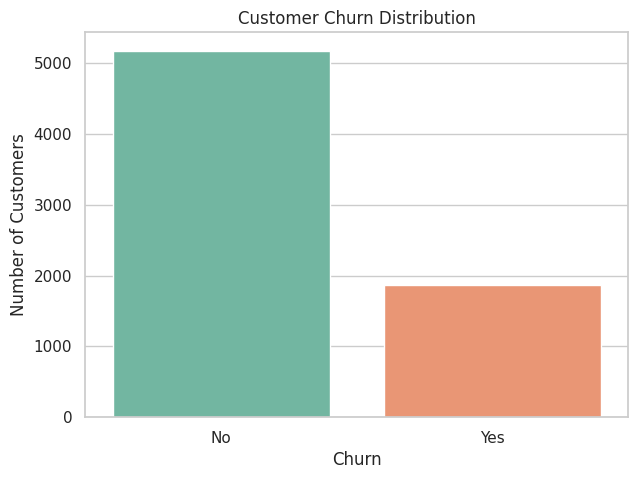

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

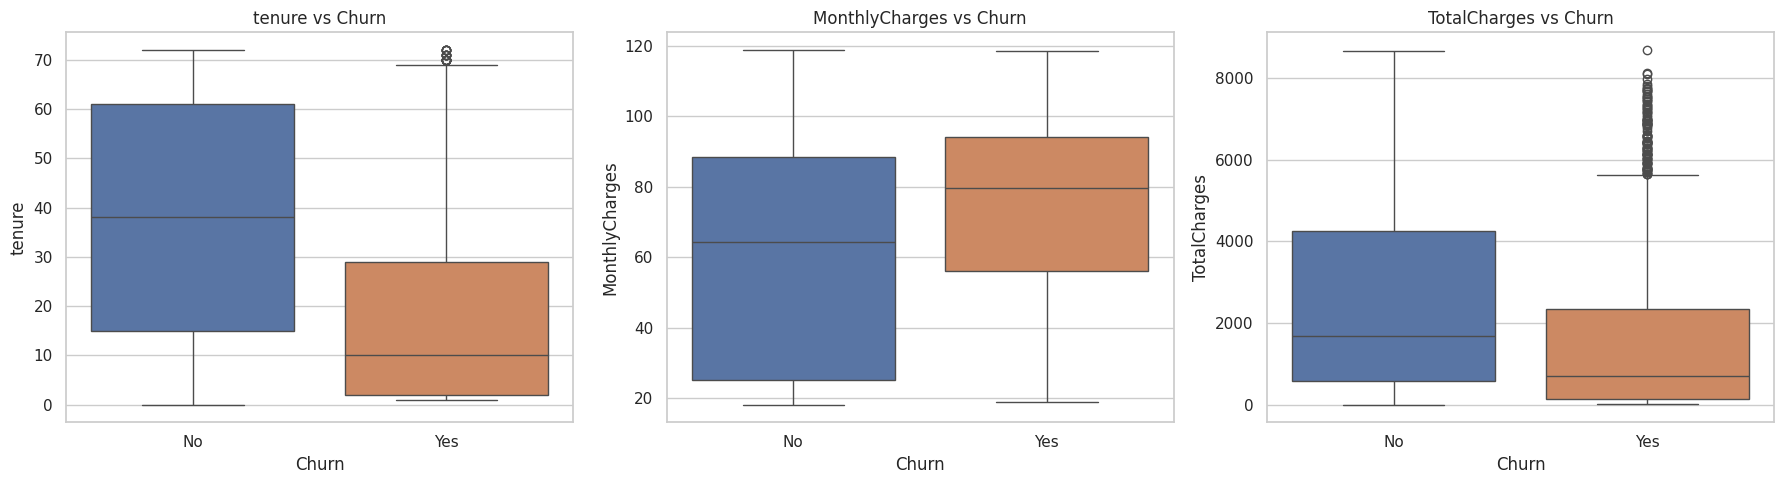

In [16]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(numeric_features):
    sns.boxplot(
        data=df,
        x="Churn",
        y=col,
        hue="Churn",
        legend=False,
        ax=axes[i]
    )
    axes[i].set_title(f"{col} vs Churn")

plt.tight_layout()
plt.show()

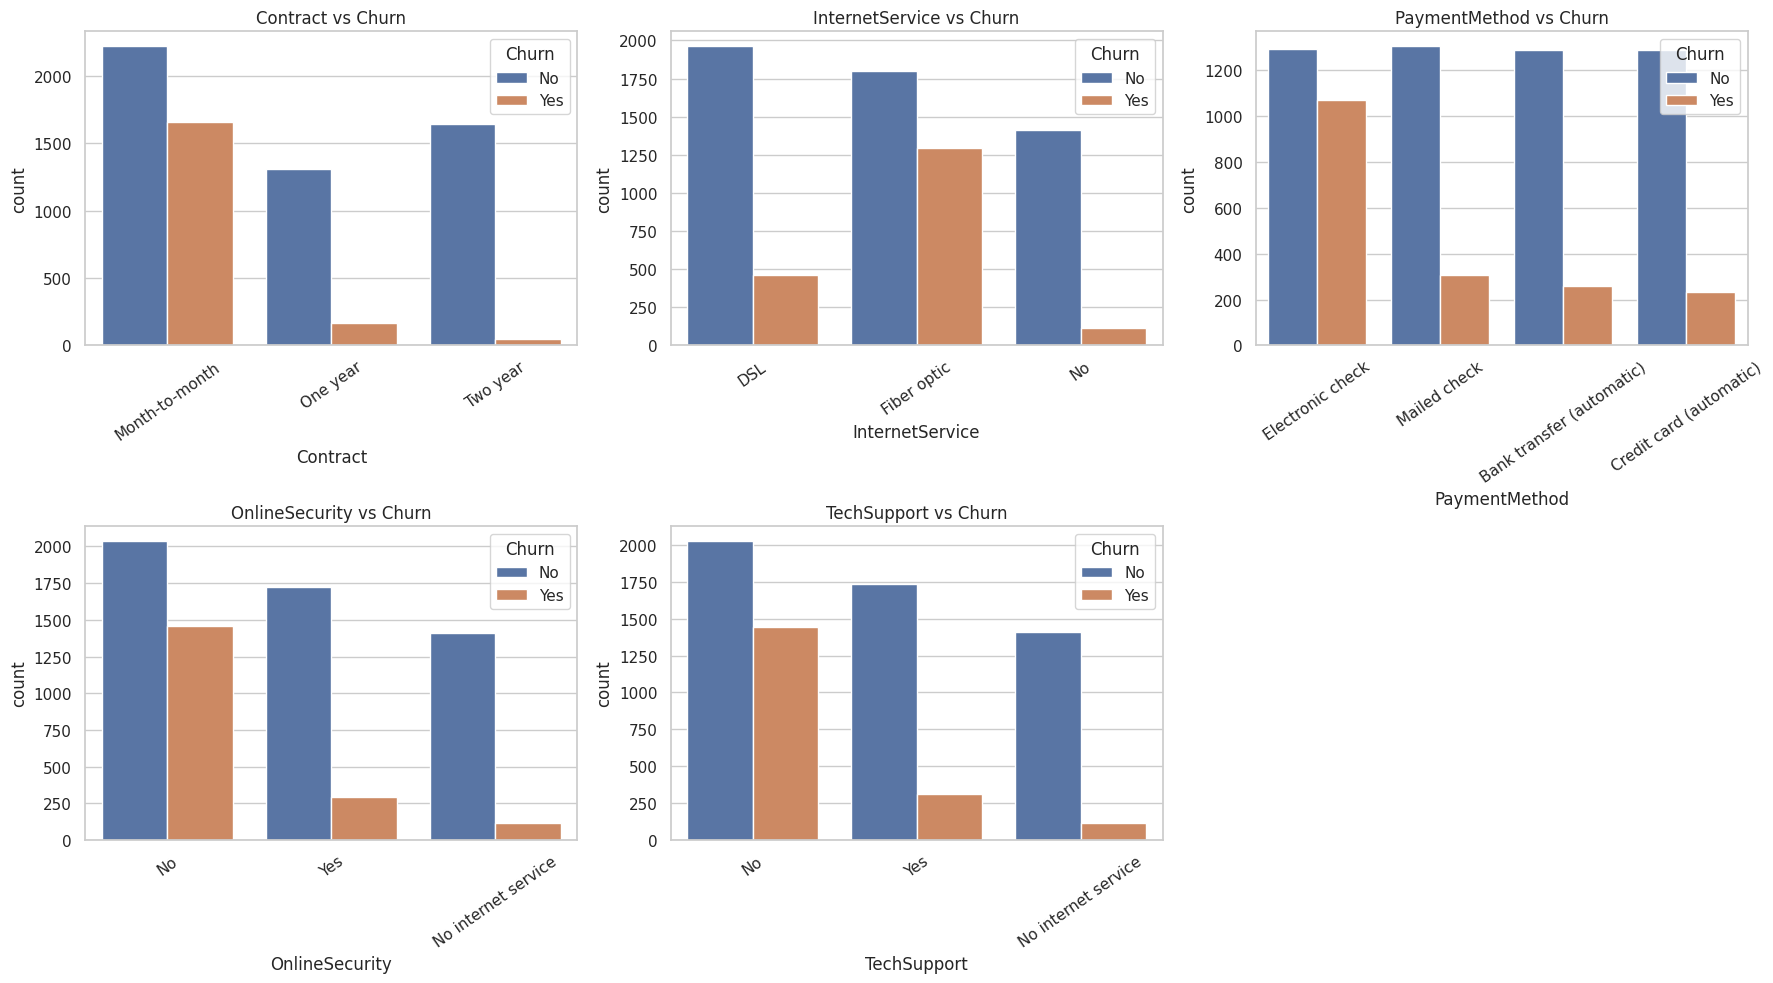

In [17]:
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, col in enumerate(categorical_features):
    ax = axes[i // 3, i % 3]

    sns.countplot(
        data=df,
        x=col,
        hue="Churn",
        ax=ax
    )

    ax.set_title(f"{col} vs Churn")
    ax.tick_params(axis="x", rotation=35)

axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

In [18]:
X = df.drop(columns=["Churn", "customerID"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [19]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("---"*30)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
------------------------------------------------------------------------------------------
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [20]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)



Training set: (5634, 19)
Testing set: (1409, 19)


In [22]:
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))




Training target distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64


In [23]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),


    "XGBoost": XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=1
)
}

In [24]:
baseline_results = []
baseline_pipelines = {}

for name, model in models.items():

    print(f"Training {name}...")

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    }

    baseline_results.append(results)
    baseline_pipelines[name] = pipe



Training Logistic Regression...
Training KNN...
Training Decision Tree...
Training Random Forest...
Training XGBoost...


In [25]:
baseline_df = pd.DataFrame(baseline_results)

baseline_df = baseline_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

display(baseline_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8416
4,XGBoost,0.8020,0.6610,0.5214,0.5830,0.8415
3,Random Forest,0.7828,0.6189,0.4733,0.5364,0.8232
1,KNN,0.7637,0.5527,0.5749,0.5636,0.7896
2,Decision Tree,0.7317,0.4946,0.4866,0.4906,0.6537


In [26]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [27]:
param_grids = {

    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__solver": ["liblinear", "lbfgs"],
        "model__class_weight": ["balanced", None]
    },

    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9, 11, 15],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    },

    "Decision Tree": {
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [3, 5, 7, 10, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 5],
        "model__class_weight": ["balanced", None]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [5, 10, 20, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__class_weight": ["balanced", "balanced_subsample"]
    },
    "XGBoost": {

    "model__n_estimators": [100, 200],

    "model__max_depth": [3, 5],

    "model__learning_rate": [0.03, 0.1],

    "model__subsample": [0.8, 1.0],

    "model__colsample_bytree": [0.8, 1.0],

    "model__scale_pos_weight": [1, 2.77]
}
}

In [28]:
grid_results = []
best_models = {}

for name, params in param_grids.items():

    model = models[name]

    print("\n" + "=" * 60)
    print(f"GridSearchCV: {name}")
    print("=" * 60)

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    grid_search = GridSearchCV(
        estimator=pipe,
        param_grid=params,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_

    print("Best Parameters:", grid_search.best_params_)
    print("Best CV ROC-AUC:", grid_search.best_score_)

    grid_results.append({
        "Model": name,
        "Best CV ROC-AUC": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })


GridSearchCV: Logistic Regression
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'model__C': 10, 'model__class_weight': None, 'model__solver': 'liblinear'}
Best CV ROC-AUC: 0.8463987523734989

GridSearchCV: KNN
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'uniform'}
Best CV ROC-AUC: 0.8233863783249131

GridSearchCV: Decision Tree
Fitting 5 folds for each of 180 candidates, totalling 900 fits
Best Parameters: {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
Best CV ROC-AUC: 0.8315718807613349

GridSearchCV: Random Forest
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best Parameters: {'model__class_weight': 'balanced_subsample', 'model__max_depth': 10, 'model__min_samples_leaf': 4, 'model__min_samples_split': 10, 'model__n_estimators': 200}
Bes

In [29]:
grid_results_df = pd.DataFrame(grid_results)

display(
    grid_results_df.sort_values(
        by="Best CV ROC-AUC",
        ascending=False
    )
)

,Model,Best CV ROC-AUC,Best Parameters
4,XGBoost,0.850249,"{'model__colsample_bytree': 0.8, 'model__learn..."
3,Random Forest,0.846560,"{'model__class_weight': 'balanced_subsample', ..."
0,Logistic Regression,0.846399,"{'model__C': 10, 'model__class_weight': None, ..."
2,Decision Tree,0.831572,"{'model__class_weight': 'balanced', 'model__cr..."
1,KNN,0.823386,"{'model__n_neighbors': 15, 'model__p': 1, 'mod..."


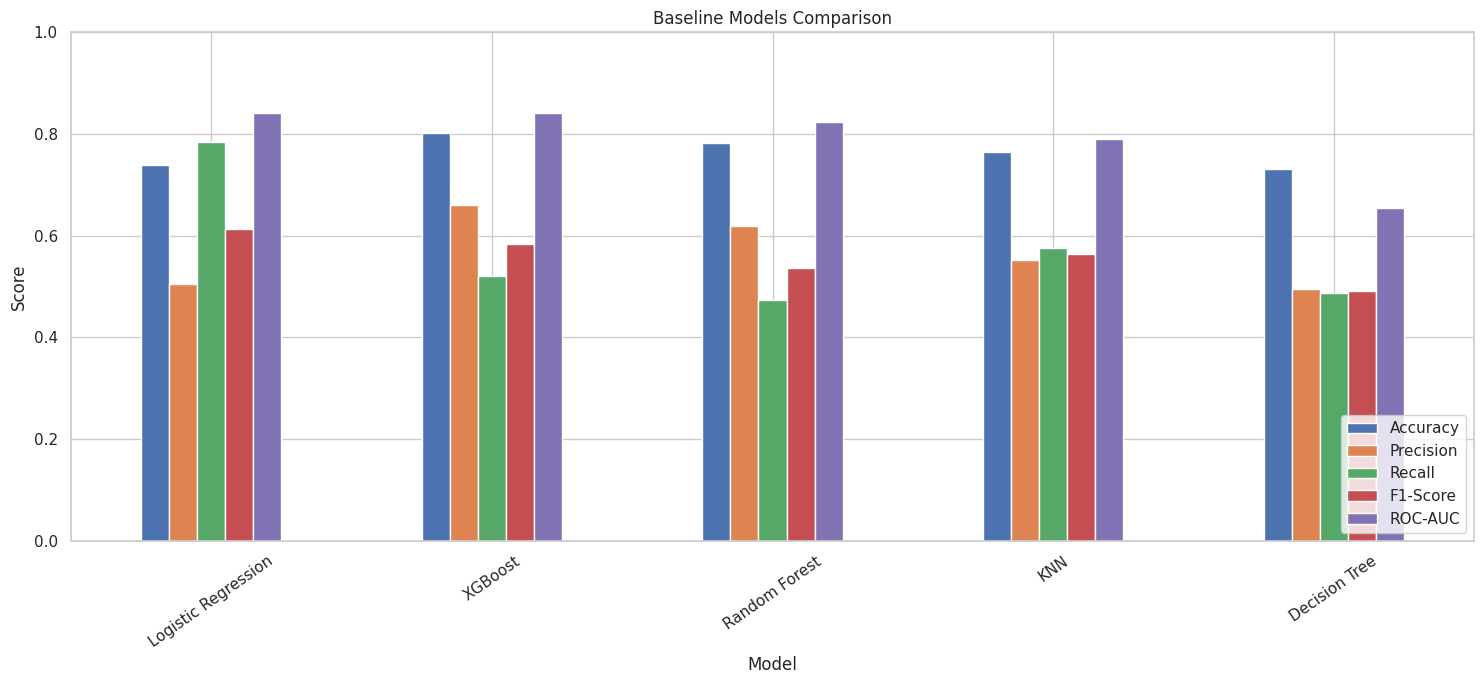

In [30]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

baseline_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(15, 7)
)

plt.title("Baseline Models Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=35)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [31]:
tuned_results = []

for name, model in best_models.items():

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

tuned_df = pd.DataFrame(tuned_results)

tuned_df = tuned_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

display(tuned_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
4,XGBoost,0.8091,0.6792,0.5321,0.5967,0.8476
3,Random Forest,0.7672,0.5453,0.7406,0.6281,0.8422
0,Logistic Regression,0.8048,0.6552,0.5588,0.6032,0.8413
2,Decision Tree,0.7537,0.5253,0.7487,0.6174,0.8371
1,KNN,0.7722,0.5734,0.5535,0.5633,0.8157


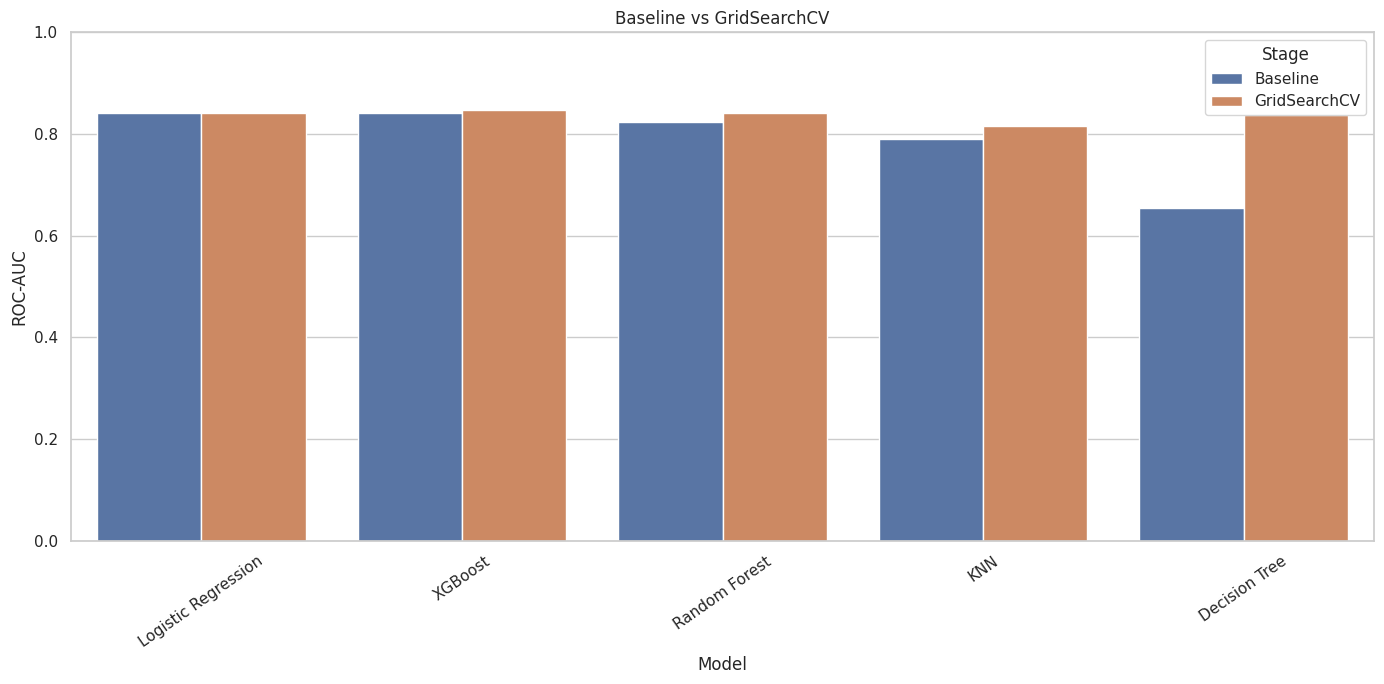

In [32]:
comparison = pd.concat([
    baseline_df.assign(Stage="Baseline"),
    tuned_df.assign(Stage="GridSearchCV")
])

plt.figure(figsize=(14, 7))

sns.barplot(
    data=comparison,
    x="Model",
    y="ROC-AUC",
    hue="Stage"
)

plt.title("Baseline vs GridSearchCV")
plt.xticks(rotation=35)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Best Model: XGBoost

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.68      0.53      0.60       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409



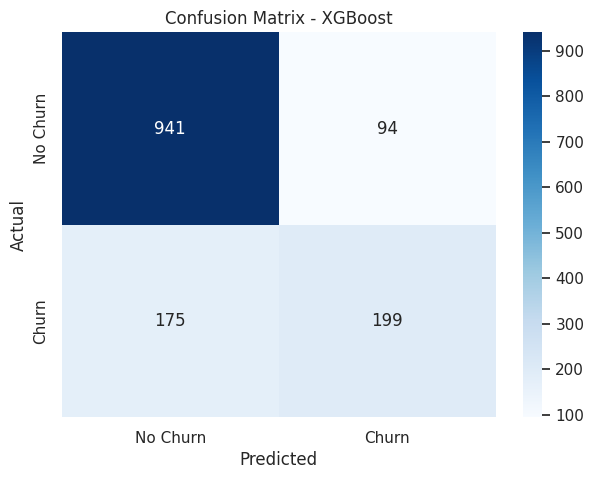

In [33]:
best_model_name = tuned_df.iloc[0]["Model"]
best_model = best_models[best_model_name]

y_pred = best_model.predict(X_test)

print("Best Model:", best_model_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

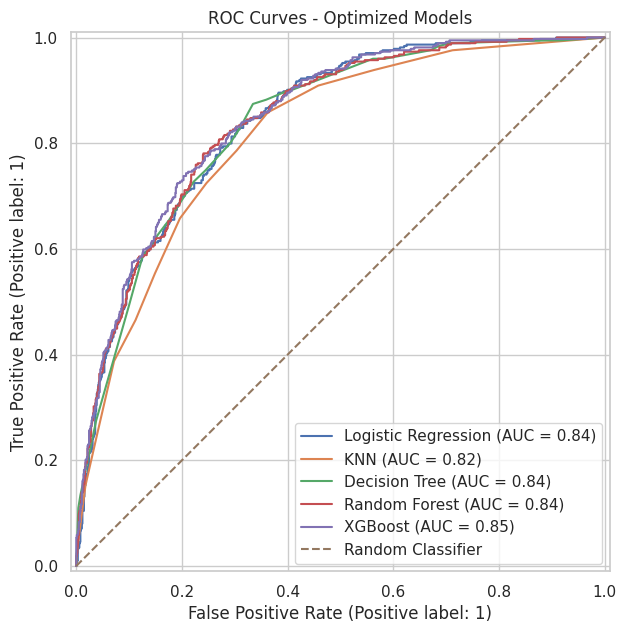

In [34]:
plt.figure(figsize=(10, 7))

for name, model in best_models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=plt.gca()
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curves - Optimized Models")
plt.legend()
plt.show()

In [35]:
y_proba = best_model.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.2, 0.81, 0.05)

threshold_results = []

for threshold in thresholds:

    y_threshold = (y_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_threshold, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.20,0.4739,0.8503,0.6086
1,0.25,0.5050,0.8102,0.6222
2,0.30,0.5351,0.7754,0.6332
3,0.35,0.5676,0.7299,0.6386
4,0.40,0.6020,0.6551,0.6274
5,0.45,0.6329,0.5856,0.6083
6,0.50,0.6792,0.5321,0.5967
7,0.55,0.7051,0.4412,0.5428
8,0.60,0.7403,0.3583,0.4829
9,0.65,0.7606,0.2888,0.4186


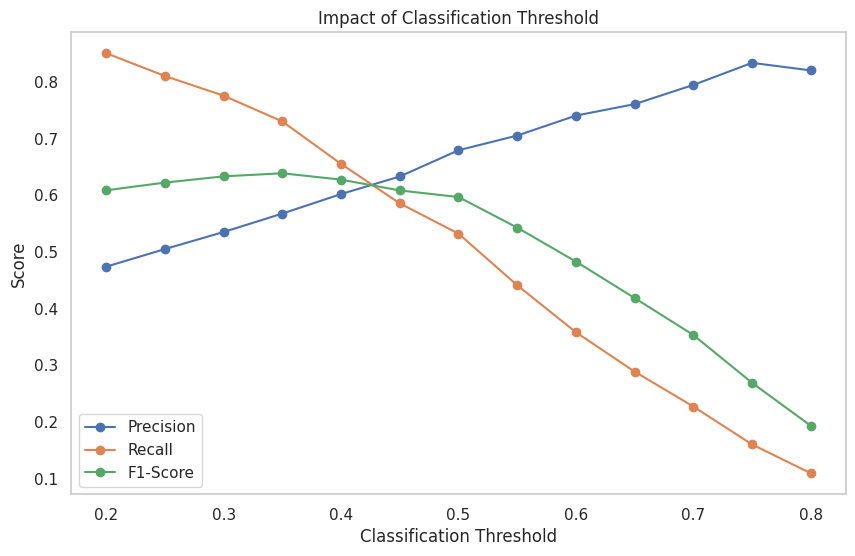

In [36]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Impact of Classification Threshold")
plt.legend()
plt.grid()
plt.show()

In [37]:
if best_model_name in ["Random Forest", "Extra Trees", "Decision Tree"]:

    feature_names = (
        best_model
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )

    importances = (
        best_model
        .named_steps["model"]
        .feature_importances_
    )

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values(
        by="Importance",
        ascending=False
    )

    plt.figure(figsize=(10, 8))

    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Features Influencing Customer Churn")
    plt.tight_layout()
    plt.show()

In [38]:
joblib.dump(
    best_model,
    "customer_churn_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [39]:
loaded_model = joblib.load(
    "customer_churn_model.pkl"
)

In [40]:
new_customer = X_test.iloc[[0]]

prediction = loaded_model.predict(new_customer)[0]

probability = loaded_model.predict_proba(
    new_customer
)[0][1]

print("Prediction:", "Churn" if prediction == 1 else "No Churn")
print(f"Churn Probability: {probability:.2%}")

Prediction: No Churn
Churn Probability: 3.07%
